### EasyOCR

Neither CUDA nor MPS are available - defaulting to CPU. Note: This module is much faster with a GPU.



Texto: Recuento de puntos (método de victoria opcional)
Probabilidad: 0.74
Contenedor: ((96, 36), (1094, 108))

Texto: Cuando un jugador gana una mano; recibe puntos en función de las cartas que quedan
Probabilidad: 0.87
Contenedor: ((90, 118), (1518, 192))

Texto: en las
Probabilidad: 0.94
Contenedor: ((1513, 155), (1589, 199))

Texto: manos de sus oponentes.
Probabilidad: 0.81
Contenedor: ((94, 176), (528, 226))

Texto: Las cartas se valoran de la siguiente manera:
Probabilidad: 0.85
Contenedor: ((86, 250), (850, 306))

Texto: Cartas del 1al 9
Probabilidad: 1.00
Contenedor: ((236, 328), (516, 376))

Texto: Su valor numérico
Probabilidad: 1.00
Contenedor: ((990, 338), (1304, 386))

Texto: Roba una
Probabilidad: 0.77
Contenedor: ((231, 391), (403, 435))

Texto: 10 puntos
Probabilidad: 1.00
Contenedor: ((994, 398), (1175, 450))

Texto: Roba cinco; Cambio de sentido
Probabilidad: 0.84
Contenedor: ((228, 450), (774, 500))

Texto: Pierde el turno; Flip
Probabilidad: 0.53
Contenedor: ((226

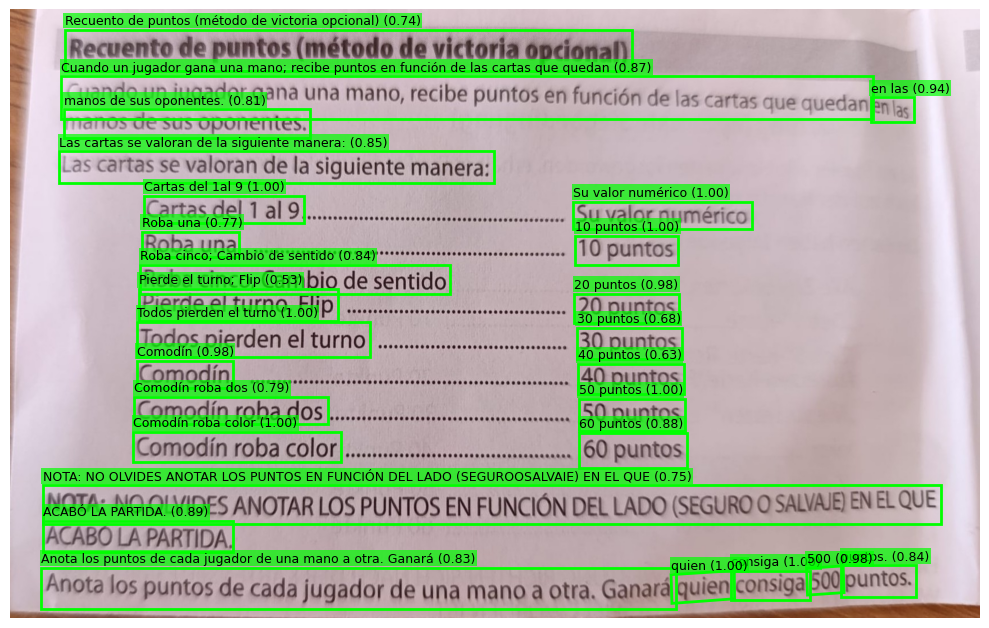

In [17]:
import easyocr
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# Carga del modelo de lengua
reader = easyocr.Reader(['es'])
path_image = 'Test.jpg'

# Reconocimiento de una imagen
res = reader.readtext(path_image)

#Con restricción de caracteres reconocibles
#result = reader.readtext(path_image, allowlist ='0123456789')

# Preparar la figura con la imagen
img = plt.imread(path_image)
fig, ax = plt.subplots(figsize=(10, 10))
ax.imshow(img)
ax.axis('off')

for (bbox, text, prob) in res:
    (top_left, top_right, bottom_right, bottom_left) = bbox
    print(f'\nTexto: {text}\nProbabilidad: {prob:.2f}\n'
          f'Contenedor: {tuple(map(int, top_left)), tuple(map(int, bottom_right))}')

    # Recuadro alrededor del texto detectado
    ax.add_patch(patches.Polygon(bbox, closed=True, fill=False,
                                 edgecolor='lime', linewidth=2))

    # Texto reconocido, justo encima del recuadro
    ax.text(top_left[0], top_left[1] - 5, f'{text} ({prob:.2f})',
            color='black', fontsize=9, va='bottom',
            bbox=dict(facecolor='lime', alpha=0.7, pad=1, edgecolor='none'))

plt.tight_layout()
plt.savefig(path_image.replace('.jpg', '_output_Easy_OCR.jpg'), dpi=300, bbox_inches='tight')
plt.show()

### Tesseract

['eng', 'osd', 'spa', 'spa_old']
Recuento de puntos (método de victoria opcional)

cuando un jugador gana una mano, recibe puntos en función de las cartas que quedan en las
manos de sus oponentes,

Las cartas se valoran de la siguiente manera:

Caras del Val O ni rica Su valor numérico
Roba una ta a RA le carcaccilós 10 puntos

Roba cinco, Cambio de sentido

Pierde el UNO UAT coacción 20 puntos

Todos pierden el turno ........u..commsssssms» 30 puntos
Comodin A A atacan 40 puntos
Comodin robados ir arcaicas 50 puntos
Comodín roba Colo ii coacción 60 puntos

NOTA: NO OLVIDES ANOTAR LOS PUNTOS EN FUNCIÓN DEL LADO (SEGURO O SALVAJE) EN EL QUE
ACABÓ LA PARTIDA.

Anota los puntos de cada jugador de una mano a otra. Ganará quien consiga 500 puntos.

Texto: Recuento (96.00%)
Contenedor: (105, 52, 287, 86)
Texto: de (96.00%)
Contenedor: (296, 47, 345, 86)
Texto: puntos (96.00%)
Contenedor: (355, 49, 494, 95)
Texto: (método (96.00%)
Contenedor: (503, 44, 674, 93)
Texto: de (97.00%)
Contenedor: 

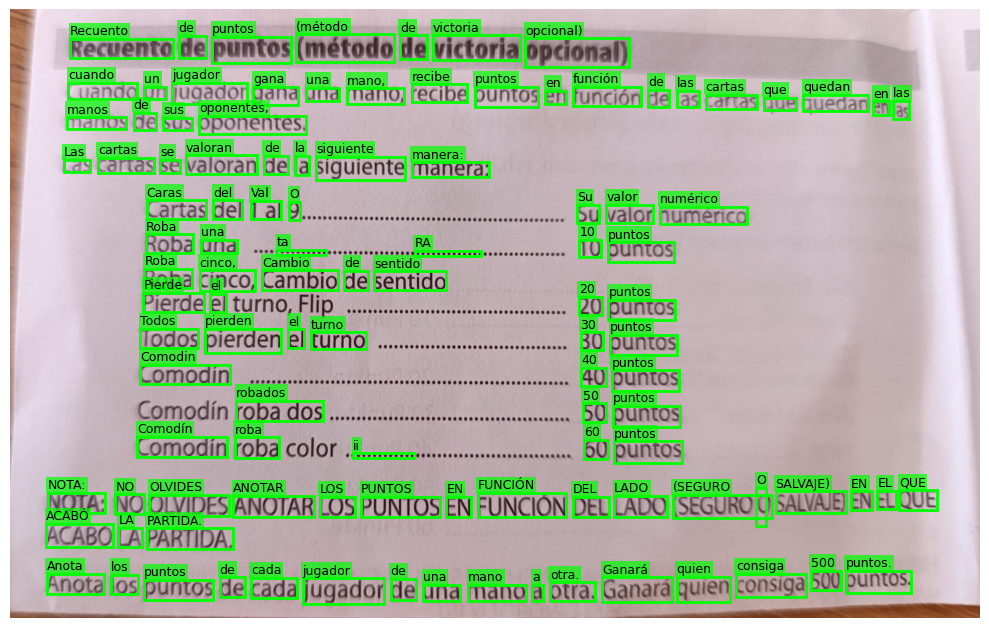

In [ ]:

# Tesseract
import cv2
import pytesseract
from pytesseract import Output
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# Si la ruta de Tesseract no está en el PATH, ruta al ejecutable
pytesseract.pytesseract.tesseract_cmd = r'C:/Program Files/Tesseract-OCR/tesseract'

# Lenguajes disponibles
print(pytesseract.get_languages(config=''))

path_image = 'Test.jpg'
img = cv2.imread(path_image)

if img is not None:
    # Convierte a RGB antes de procesar
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    # Texto completo
    print(pytesseract.image_to_string(img_rgb, lang='spa'))

    # Texto y localización de cada palabra
    d = pytesseract.image_to_data(img_rgb, lang='spa', output_type=Output.DICT)

    # Preparar la figura con la imagen
    fig, ax = plt.subplots(figsize=(10, 10))
    ax.imshow(img_rgb)
    ax.axis('off')

    n_boxes = len(d['text'])
    for i in range(n_boxes):
        text = d['text'][i].strip()
        conf = float(d['conf'][i])

        # Ignorar detecciones vacías o poco fiables
        if conf > 30 and text:
            (x, y, w, h) = (d['left'][i], d['top'][i], d['width'][i], d['height'][i])

            print(f'Texto: {text} ({conf:.2f}%)\nContenedor: {x, y, x + w, y + h}')

            # Recuadro alrededor de la palabra
            ax.add_patch(patches.Rectangle((x, y), w, h, fill=False,
                                           edgecolor='lime', linewidth=2))

            # Palabra reconocida, justo encima del recuadro
            ax.text(x, y - 3, text, color='black', fontsize=9, va='bottom',
                    bbox=dict(facecolor='lime', alpha=0.7, pad=1, edgecolor='none'))

    plt.tight_layout()
    plt.savefig(path_image.replace('.jpg', '_output_Tesseract.jpg'), dpi=200, bbox_inches='tight')  # guarda el resultado
    plt.show()

else:
    print('Error de imagen')

### PaddleOCR

C:\Users\jisal\AppData\Local\Temp\ipykernel_40444\1020733631.py:5: DeprecationWarning: The parameter `use_angle_cls` has been deprecated and will be removed in the future. Please use `use_textline_orientation` instead.
  ocr = PaddleOCR(use_angle_cls=True, lang='es')  # need to run only once to download and load model into memory
Creating model: ('PP-LCNet_x1_0_doc_ori', None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `C:\Users\jisal\.paddlex\official_models\PP-LCNet_x1_0_doc_ori`.
Creating model: ('UVDoc', None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `C:\Users\jisal\.paddlex\official_models\UVDoc`.
Creating model: ('PP-LCNet_x1_0_textline_ori', None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `C:\Users\jisal\.paddlex\official_models\PP-LCNet_x1_0_textline_ori`.
Creating model: ('PP-OCRv5_server_det', None)
Model

['Esto', 'pouebs', 'para', 'es', 'Una', 'los', 'letra', 'OCR. M.', 'no', 'es', 'y', 'podeia', 'mejor', 'pero', 'loveno', 'ser', 'peor,', 'podria', 'aqui', 'porer', '1', 'Ibupolens y', 'sabecto.', 'OU'] [0.9994903802871704, 0.853615939617157, 0.9960806369781494, 0.8498003482818604, 0.9658252596855164, 0.9633357524871826, 0.9564976692199707, 0.8109911680221558, 0.9550031423568726, 0.9894274473190308, 0.21958093345165253, 0.8752568364143372, 0.8619638681411743, 0.8591457009315491, 0.8845267295837402, 0.7017197608947754, 0.9158722162246704, 0.8976966738700867, 0.8771762251853943, 0.81981360912323, 0.5499802827835083, 0.8611224889755249, 0.8052376508712769, 0.5312185883522034]

Text: Esto
Probability: 1.00
Box: ((147, 134), (454, 358))

Text: pouebs
Probability: 0.85
Box: ((1123, 164), (1466, 361))

Text: para
Probability: 1.00
Box: ((1565, 198), (1802, 352))

Text: es
Probability: 0.85
Box: ((575, 221), (694, 333))

Text: Una
Probability: 0.97
Box: ((823, 215), (1012, 328))

Text: los
Prob

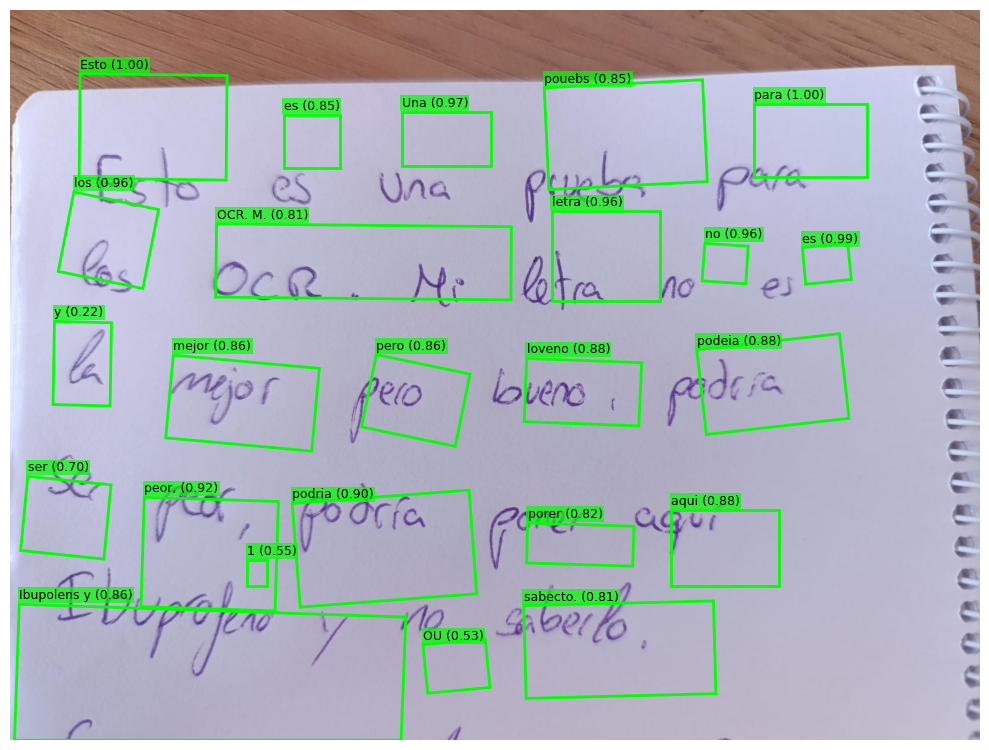

In [ ]:
#https://github.com/PADDLEPADDLE/PADDLEOCR
from paddleocr import PaddleOCR
import matplotlib.pyplot as plt
import matplotlib.patches as patches

ocr = PaddleOCR(use_angle_cls=True, lang='es')  # need to run only once to download and load model into memory
img_path = 'Test_manual.jpg'
result = ocr.predict(img_path)[0]

texts = result['rec_texts']
scores = result['rec_scores']
polys = result['rec_polys']  # one 4-point polygon per recognized text

print(texts, scores)

# Prepare the figure with the image
fig, ax = plt.subplots(figsize=(10, 10))
ax.imshow(plt.imread(img_path))
ax.axis('off')

for poly, text, score in zip(polys, texts, scores):
    print(f'\nText: {text}\nProbability: {score:.2f}\n'
          f'Box: {tuple(map(int, poly[0])), tuple(map(int, poly[2]))}')

    # Box around the detected text
    ax.add_patch(patches.Polygon(poly, closed=True, fill=False,
                                 edgecolor='lime', linewidth=2))

    # Recognized text, just above the top-left corner of the box
    x, y = poly[0]
    ax.text(x, y - 5, f'{text} ({score:.2f})',
            color='black', fontsize=9, va='bottom',
            bbox=dict(facecolor='lime', alpha=0.7, pad=1, edgecolor='none'))

plt.tight_layout()
plt.savefig(img_path.replace('.jpg', '_output_Paddle.jpg'), dpi=200, bbox_inches='tight')  # save the result
plt.show()

### Unlimited-OCR Baidu

In [ ]:
# https://github.com/baidu/Unlimited-OCR
import os
import torch
from transformers import AutoModel, AutoTokenizer

# Para que funcione con respecto al de SmolVLM.

# pip install addict
# pip install einops
# pip install easydict
# pip install transformers==4.57.1
 

# Aparentemente tienen llamadas a cuda en el proceso de inferencia, por lo que si no tenemos GPU falla.
# Vamos a hacer que esas llamadas sean no-ops si no hay GPU disponible. 
if not torch.cuda.is_available():
    torch.Tensor.cuda = lambda self, *a, **k: self
    torch.nn.Module.cuda = lambda self, *a, **k: self
    
model_name = 'baidu/Unlimited-OCR'
path_image = 'Test.jpg'
tokenizer = AutoTokenizer.from_pretrained(model_name, trust_remote_code=True)
model = AutoModel.from_pretrained(
    model_name,
    trust_remote_code=True,
    use_safetensors=True,
    torch_dtype=torch.bfloat16,
)
model = model.eval().cuda()

# ── Single image supports two configs: gundam or base ──
# gundam: base_size=1024, image_size=640, crop_mode=True
# base: base_size=1024, image_size=1024, crop_mode=False
model.infer(
    tokenizer,
    prompt='<image>document parsing.',
    image_file=path_image,
    output_path=path_image.replace('.jpg', '_output_Unlimited'),
    base_size=1024, image_size=640, crop_mode=True,
    max_length=32768,
    no_repeat_ngram_size=35, ngram_window=128,
    save_results=True,
)


c:\Users\jisal\miniconda3\envs\baiduOCR\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
`torch_dtype` is deprecated! Use `dtype` instead!
Some weights of UnlimitedOCRForCausalLM were not initialized from the model checkpoint at baidu/Unlimited-OCR and are newly initialized: ['model.vision_model.embeddings.position_ids']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
The attention mask and the pad token id were not set. As a consequence, you may observe unexpected behavior. Please pass your input's `attention_mask` to obtain reliable results.
Setting `pad_token_id` to `eos_token_id`:1 for open-end generation.
Both `max_new_tokens` (=32768) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/tr

<|det|>title [56, 38, 641, 98]<|/det|>Recuento de puntos (método de victoria opcional)
<|det|>text [48, 113, 930, 208]<|/det|>Cuando un jugador gana una mano, recibe puntos en función de las cartas que quedan en las manos de sus oponentes.
<|det|>text [47, 233, 497, 283]<|/det|>Las cartas se valoran de la siguiente manera:
<|det|>text [134, 306, 764, 358]<|/det|>Cartas del 1 al 9.... Su valor numérico
<|det|>text [134, 363, 686, 414]<|/det|>Roba una 10 puntos
<|det|>text [133, 420, 453, 468]<|/det|>Roba cinco, Cambio de sentido
<|det|>text [133, 468, 686, 513]<|/det|>Pierde el turno, Flip 20 puntos
<|det|>text [131, 520, 688, 568]<|/det|>Todos pierden el turno 30 puntos
<|det|>text [130, 577, 692, 628]<|/det|>Comodín 40 puntos
<|det|>text [129, 636, 692, 686]<|/det|>Comodín roba dos 50 puntos
<|det|>text [128, 696, 695, 746]<|/det|>Comodín roba color 60 puntos
<|det|>text [31, 787, 959, 894]<|/det|>NOTA: NO OLVIDES ANOTAR LOS PUNTOS EN FUNCIÓN DEL LADO (SEGURO O SALVAJE) EN EL QUE ACAB

image: 0it [00:00, ?it/s]
other: 100%|██████████| 13/13 [00:00<?, ?it/s]


### SmolVLM

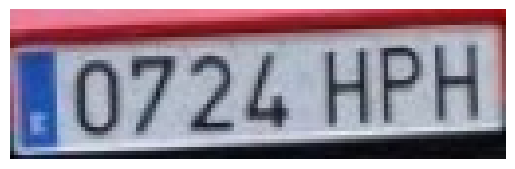

User:<row_1_col_1><row_1_col_2><row_1_col_3><row_1_col_4>
<row_2_col_1><row_2_col_2><row_2_col_3><row_2_col_4>

<global-img>Can you give me the text in the license plate of the image?
Assistant: 0724HPH


In [4]:
from transformers import AutoProcessor, AutoModelForImageTextToText
import torch
Device = "cpu"  # or "cpu"

processor = AutoProcessor.from_pretrained("HuggingFaceTB/SmolVLM-Instruct")
model = AutoModelForImageTextToText.from_pretrained("HuggingFaceTB/SmolVLM-Instruct",
                                                dtype=torch.bfloat16,
                                                _attn_implementation="flash_attention_2" if Device == "cuda" else "eager").to(Device)

from PIL import Image
from transformers.image_utils import load_image
from matplotlib import pyplot as plt

# Load images

image_1 = Image.open('matricula.jpg')
# Create input messages
messages = [
    {
        "role": "user",
        "content": [
            {"type": "image"},
            {"type": "text", "text": "Can you give me the text in the license plate of the image?"}
        ]
    },
]

# Prepare inputs
prompt = processor.apply_chat_template(messages, add_generation_prompt=True)
inputs = processor(text=prompt, images=[image_1], return_tensors="pt")
inputs = inputs.to(Device)

generated_ids = model.generate(**inputs, max_new_tokens=10)
generated_texts = processor.batch_decode(
    generated_ids,
    skip_special_tokens=True,
)

plt.imshow(image_1)
plt.axis('off')
plt.show()
print(generated_texts[0])